# IA101 — Notebook 1 — Introduction aux mathématiques de l'apprentissage machine

**Durée : 40 minutes** · Objectif visé : **O2** — expliquer le fonctionnement de l'apprentissage

Derrière `.fit()`, la plupart des méthodes d'apprentissage supervisé suivent le même schéma :

1. on choisit une **famille de modèles** paramétrée ;
2. on définit une **fonction de perte** qui mesure l'erreur des prédictions ;
3. on **minimise** cette perte par rapport aux paramètres, par exemple par **descente de gradient** ;
4. on vérifie que le modèle **généralise** à des données qu'il n'a pas vues.

Ce notebook développe chacune de ces étapes sur un exemple simple : prédire le délai d'arrivée d'une ambulance en fonction de la distance à parcourir.

### Plan
1. Le modèle et ses paramètres
2. La fonction de perte
3. Le paysage de la perte
4. Le gradient : calcul analytique
5. La descente de gradient et le taux d'apprentissage
6. Comparaison avec la solution de scikit-learn
7. La généralisation

In [ ]:
# @title
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Curseurs interactifs : interact relie un curseur à une fonction Python
from ipywidgets import interact, FloatSlider

# Réglages communs à toutes les figures du notebook
plt.rcParams.update({
    "figure.dpi": 110,            # résolution des figures (points par pouce)
    "axes.spines.top": False,     # retire la bordure du haut
    "axes.spines.right": False,   # retire la bordure de droite
})

rng = np.random.default_rng(42)     # Générateur de nombres aléatoires ; N.B : Le nombre 42 n’a rien de spécial. N’importe quel entier positif convient.
# Données simulées : 40 interventions d'ambulance
# Distance tirée au hasard, de façon uniforme, entre 1 et 20 km
distance = rng.uniform(1, 20, 40)                       # variable explicative x (km)

# Délai = 1,8 min par km + 4 min de base + bruit aléatoire (moyenne 0, écart-type 3 min)
delai = 1.8 * distance + 4 + rng.normal(0, 3, 40)       # variable cible y (min)
print(f"n = {len(distance)} interventions ; distance de {distance.min():.1f} à {distance.max():.1f} km")

n = 40 interventions ; distance de 1.8 à 19.5 km


La pente de 1,8 et l’ordonnée à l’origine de 4 sont les « vraies » valeurs de la simulation : en pratique, elles sont inconnues, et c’est le modèle qui doit les estimer à partir des données. Le bruit représente tout ce que la distance n’explique pas, comme la circulation ou la météo.

## 1. Le modèle et ses paramètres

On fait l'hypothèse d'une relation affine entre la distance $x$ et le délai $y$ :

$$\hat{y} = f_{a,b}(x) = a\,x + b$$

- $a$ : minutes supplémentaires par kilomètre ;
- $b$ : délai fixe (mobilisation, départ).

$a$ et $b$ sont les **paramètres** du modèle. Chaque couple $(a, b)$ définit une droite différente. **Apprendre consiste à choisir les valeurs de $(a, b)$ qui rendent les prédictions $\hat{y}_i$ les plus proches possible des valeurs observées $y_i$.**

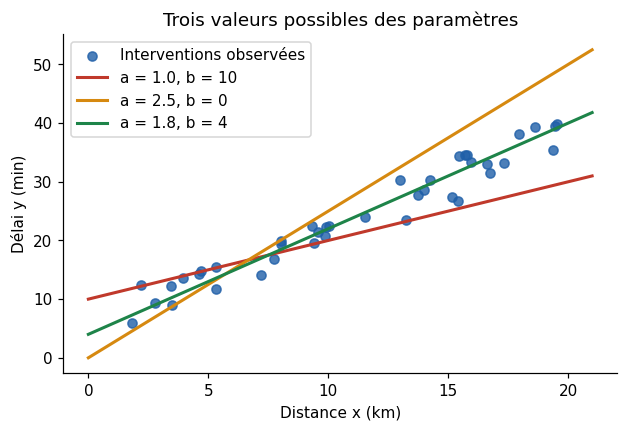

In [ ]:
x_ligne = np.linspace(0, 21, 50)
plt.figure(figsize=(6.5, 4))
plt.scatter(distance, delai, color="#1f5fa8", alpha=0.8, label="Interventions observées")
for a, b, c in [(1.0, 10, "#c0392b"), (2.5, 0, "#d68910"), (1.8, 4, "#1e8449")]:
    plt.plot(x_ligne, a * x_ligne + b, color=c, lw=2, label=f"a = {a}, b = {b}")
plt.xlabel("Distance x (km)"); plt.ylabel("Délai y (min)")
plt.title("Trois valeurs possibles des paramètres"); plt.legend(); plt.show()

**Prédiction.** Laquelle de ces trois droites est la meilleure ? Comment le mesurer objectivement ?

## 2. La fonction de perte

Pour chaque observation, le **résidu** $\hat{y}_i - y_i$ est l'écart entre prédiction et observation. On agrège ces écarts en un seul nombre, l'**erreur quadratique moyenne** (EQM) :

$$L(a, b) = \frac{1}{n} \sum_{i=1}^{n} \left(a\,x_i + b - y_i\right)^2$$

- Le carré empêche les erreurs positives et négatives de se compenser, et pénalise davantage les grandes erreurs.
- $L$ est une **fonction des paramètres** : les données sont fixées, seuls $a$ et $b$ varient.
- **Le meilleur modèle est celui qui minimise $L$.**

### Exercice 2 — Implémenter la fonction de perte

In [ ]:
def eqm(predit, observe):
    """Erreur quadratique moyenne."""
    return ...  # À COMPLÉTER

for a, b in [(1.0, 10), (2.5, 0), (1.8, 4)]:
    print(f"a = {a}, b = {b:>2}  ->  EQM = {eqm(a * distance + b, delai):.2f}")

a = 1.0, b = 10  ->  EQM = 27.85
a = 2.5, b =  0  ->  EQM = 37.04
a = 1.8, b =  4  ->  EQM = 4.67


<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
def eqm(predit, observe):
    """Erreur quadratique moyenne."""
    return np.mean((predit - observe) ** 2)

for a, b in [(1.0, 10), (2.5, 0), (1.8, 4)]:
    print(f"a = {a}, b = {b:>2}  ->  EQM = {eqm(a * distance + b, delai):.2f}")
```

</details>

### Activité — Ajuster le modèle manuellement

Utilisez les curseurs pour obtenir la plus petite EQM possible. Notez votre meilleur résultat : il sera comparé à la solution optimale à la section 6. Les segments rouges représentent les résidus.

In [ ]:
def tracer_modele(a=1.0, b=10.0):
    predit = a * distance + b
    plt.figure(figsize=(6.5, 4))
    plt.vlines(distance, predit, delai, color="#c0392b", alpha=0.5, label="Résidus")
    plt.scatter(distance, delai, color="#1f5fa8", zorder=3, label="Observations")
    plt.plot(x_ligne, a * x_ligne + b, color="black", lw=2, label="Modèle")
    plt.ylim(0, 50); plt.xlabel("Distance x (km)"); plt.ylabel("Délai y (min)")
    plt.title(f"EQM = {eqm(predit, delai):.2f}", fontsize=13, fontweight="bold")
    plt.legend(loc="upper left"); plt.show()

interact(tracer_modele,
         a=FloatSlider(min=0, max=4, step=0.05, value=1.0, description="pente a"),
         b=FloatSlider(min=-10, max=20, step=0.25, value=10.0, description="ordonnée b"));

interactive(children=(FloatSlider(value=1.0, description='pente a', max=4.0, step=0.05), FloatSlider(value=10.…

## 3. Le paysage de la perte

En évaluant $L(a, b)$ sur une grille de valeurs, on obtient une **surface**, représentée ici par ses courbes de niveau. Chaque point du plan est un modèle ; la couleur indique sa perte. Le meilleur modèle se situe au **minimum** de la surface.

Pour l'EQM d'un modèle linéaire, cette surface est un **paraboloïde convexe** : elle possède un unique minimum.

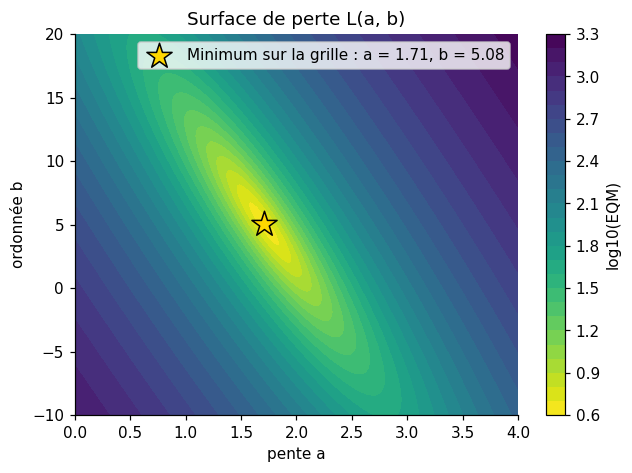

In [ ]:
grille_a = np.linspace(0, 4, 200)
grille_b = np.linspace(-10, 20, 200)
A, B = np.meshgrid(grille_a, grille_b)
pertes = ((A[..., None] * distance + B[..., None] - delai) ** 2).mean(axis=-1)
i_min = np.unravel_index(pertes.argmin(), pertes.shape)

plt.figure(figsize=(6.5, 4.5))
niveaux = plt.contourf(A, B, np.log10(pertes), levels=30, cmap="viridis_r")
plt.colorbar(niveaux, label="log10(EQM)")
plt.scatter(A[i_min], B[i_min], marker="*", s=300, color="gold", edgecolor="black",
            label=f"Minimum sur la grille : a = {A[i_min]:.2f}, b = {B[i_min]:.2f}")
plt.xlabel("pente a"); plt.ylabel("ordonnée b"); plt.title("Surface de perte L(a, b)")
plt.legend(loc="upper right"); plt.show()

Ici, deux paramètres permettent de parcourir toute la surface. Un modèle réaliste en compte des milliers, voire des milliards pour un grand modèle de langage : l'exploration exhaustive devient impossible. On a besoin d'une information **locale** qui indique dans quelle direction se déplacer : le **gradient**.

### Image mentale : marcher dans une vallée, dans le brouillard

Imaginez que vous cherchez le point le plus bas d/'une vallée, dans un brouillard si épais que vous ne voyez que le sol sous vos pieds.

| Dans la vallée | Dans le modèle |
|---|---|
| Votre position | Les valeurs des paramètres |
| Votre altitude | La perte (l/'erreur du modèle) |
| La pente sous vos pieds | Le gradient |
| Le fond de la vallée | Les meilleurs paramètres |

Vous ne pouvez pas voir toute la vallée, mais vous sentez la pente. La stratégie est donc simple : **faire un pas vers la descente, puis recommencer.**

Pour le visualiser, on fige $b$ et on ne fait varier que $a$. Le paysage devient alors une simple courbe en U. Avec les deux paramètres, cette courbe devient un bol, et la carte ci-dessus montre ce bol vu du dessus.

- **Gradient négatif :** la courbe descend vers la droite, il faut augmenter $a$.
- **Gradient positif :** la courbe monte vers la droite, il faut diminuer $a$.
- **Gradient proche de zéro :** on est au fond de la vallée.

In [ ]:
# @title
# On fige l'ordonnée b : la perte ne dépend plus que de la pente a
b_fixe = 4.0
grille_a = np.linspace(0, 4, 200)
pertes_a = np.array([np.mean((a * distance + b_fixe - delai) ** 2) for a in grille_a])
a_min = grille_a[pertes_a.argmin()]


def tracer_pente(a=0.5):
    perte = np.mean((a * distance + b_fixe - delai) ** 2)
    gradient = 2 * np.mean((a * distance + b_fixe - delai) * distance)  # pente de la courbe en a

    plt.figure(figsize=(7, 4.3))
    plt.plot(grille_a, pertes_a, color="#1f5fa8", lw=2.5, label="Perte L(a)")

    # Tangente : la seule information disponible à l'endroit où l'on se trouve
    x_tan = np.array([a - 0.45, a + 0.45])
    plt.plot(x_tan, perte + gradient * (x_tan - a), color="#c0392b", lw=2, label="Pente locale (gradient)")
    plt.scatter([a], [perte], s=90, color="#c0392b", edgecolor="white", zorder=4, label="Position actuelle")
    plt.scatter([a_min], [pertes_a.min()], marker="*", s=240, color="gold",
                edgecolor="black", zorder=4, label="Minimum")

    # Flèche : on se déplace dans le sens opposé au gradient
    if abs(gradient) >= 10:
        sens = -np.sign(gradient) * 0.45
        plt.annotate("", xy=(a + sens, 0.08 * pertes_a.max()), xytext=(a, 0.08 * pertes_a.max()),
                     arrowprops=dict(arrowstyle="-|>", color="black", lw=2))

    if abs(gradient) < 10:
        conseil = "gradient presque nul : on est au fond"
    elif gradient < 0:
        conseil = "gradient négatif : il faut augmenter a"
    else:
        conseil = "gradient positif : il faut diminuer a"
    plt.title(f"a = {a:.2f}, gradient = {gradient:.0f}\n{conseil}", fontsize=12, fontweight="bold")
    plt.xlabel("pente a"); plt.ylabel("Perte L(a) = EQM")
    plt.xlim(0, 4); plt.ylim(0, pertes_a.max() * 1.05)
    plt.legend(loc="upper center"); plt.show()


interact(tracer_pente, a=FloatSlider(min=0, max=4, step=0.05, value=0.5, description="pente a"));

interactive(children=(FloatSlider(value=0.5, description='pente a', max=4.0, step=0.05), Output()), _dom_class…


## 4. Le gradient : calcul analytique

Le gradient $\nabla L = \left(\frac{\partial L}{\partial a}, \frac{\partial L}{\partial b}\right)$ indique la direction de **plus forte augmentation** de la perte. Calculons-le à l'aide de la règle de dérivation des fonctions composées.

Posons $r_i = a\,x_i + b - y_i$ (le résidu). Alors $L = \frac{1}{n}\sum_i r_i^2$, avec $\frac{\partial r_i}{\partial a} = x_i$ et $\frac{\partial r_i}{\partial b} = 1$. Donc :

$$\frac{\partial L}{\partial a} = \frac{1}{n}\sum_{i=1}^{n} 2\,r_i\,\frac{\partial r_i}{\partial a} = \frac{2}{n}\sum_{i=1}^{n} \left(a\,x_i + b - y_i\right)x_i$$

$$\frac{\partial L}{\partial b} = \frac{2}{n}\sum_{i=1}^{n} \left(a\,x_i + b - y_i\right)$$

**Interprétation.** Si le modèle surestime en moyenne ($r_i > 0$), $\frac{\partial L}{\partial b} > 0$ : augmenter $b$ aggraverait l'erreur, il faut donc **diminuer** $b$.

### Exercice 3 — Vérifier le gradient numériquement

On vérifie la formule analytique en la comparant à une approximation par différences finies : $\frac{\partial L}{\partial a} \approx \frac{L(a + h, b) - L(a - h, b)}{2h}$.

In [ ]:
def gradient(a, b):
    r = a * distance + b - delai
    grad_a = ...   # À COMPLÉTER
    grad_b = ...   # À COMPLÉTER
    return grad_a, grad_b

a0, b0, h = 1.0, 10.0, 1e-5
L = lambda a, b: eqm(a * distance + b, delai)
approx_a = (L(a0 + h, b0) - L(a0 - h, b0)) / (2 * h)
approx_b = (L(a0, b0 + h) - L(a0, b0 - h)) / (2 * h)

print("Gradient analytique         :", np.round(gradient(a0, b0), 4))
print("Différences finies           :", np.round((approx_a, approx_b), 4))

Gradient analytique         : [-107.3753   -5.9006]
Différences finies           : [-107.3753   -5.9006]


<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
def gradient(a, b):
    r = a * distance + b - delai
    grad_a = 2 * np.mean(r * distance)
    grad_b = 2 * np.mean(r)
    return grad_a, grad_b

a0, b0, h = 1.0, 10.0, 1e-5
L = lambda a, b: eqm(a * distance + b, delai)
approx_a = (L(a0 + h, b0) - L(a0 - h, b0)) / (2 * h)
approx_b = (L(a0, b0 + h) - L(a0, b0 - h)) / (2 * h)

print("Gradient analytique         :", np.round(gradient(a0, b0), 4))
print("Différences finies           :", np.round((approx_a, approx_b), 4))
```

</details>

## 5. La descente de gradient

On part de paramètres initiaux, puis on se déplace de façon répétée dans la direction **opposée** au gradient :

$$a \leftarrow a - \eta\,\frac{\partial L}{\partial a} \qquad\qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

$\eta$ est le **taux d'apprentissage** : il fixe la taille de chaque pas. C'est un **hyperparamètre**, choisi par l'utilisateur et non appris.

> **Analogie.** Une randonneuse dans le brouillard ne voit pas la vallée, mais elle perçoit la pente sous ses pieds. Elle avance d'un pas dans la direction de la descente, puis recommence.

### Exercice 4 — Implémenter la descente de gradient

In [ ]:
def descente_de_gradient(taux, n_iterations=1000):
    a, b = 0.0, 0.0
    historique = []
    for _ in range(n_iterations):
        historique.append((a, b, eqm(a * distance + b, delai)))
        grad_a, grad_b = gradient(a, b)
        a =  ...   # À COMPLÉTER
        b =  ...   # À COMPLÉTER
    return a, b, np.array(historique)

a_appris, b_appris, hist = descente_de_gradient(taux=0.005)
print(f"Paramètres estimés : a = {a_appris:.3f}, b = {b_appris:.3f}")
print(f"EQM : {hist[0, 2]:.1f} au départ  ->  {hist[-1, 2]:.3f} à la fin")

Paramètres estimés : a = 1.760, b = 4.344
EQM : 670.5 au départ  ->  4.520 à la fin


<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
def descente_de_gradient(taux, n_iterations=1000):
    a, b = 0.0, 0.0
    historique = []
    for _ in range(n_iterations):
        historique.append((a, b, eqm(a * distance + b, delai)))
        grad_a, grad_b = gradient(a, b)
        a = a - taux * grad_a
        b = b - taux * grad_b
    return a, b, np.array(historique)

a_appris, b_appris, hist = descente_de_gradient(taux=0.005)
print(f"Paramètres estimés : a = {a_appris:.3f}, b = {b_appris:.3f}")
print(f"EQM : {hist[0, 2]:.1f} au départ  ->  {hist[-1, 2]:.3f} à la fin")
```

</details>

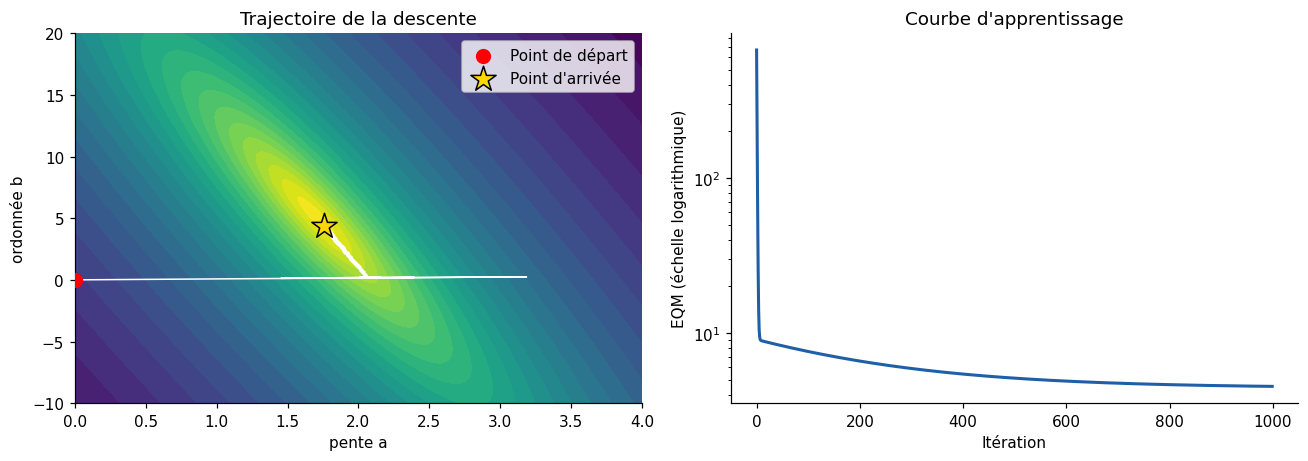

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.contourf(A, B, np.log10(pertes), levels=30, cmap="viridis_r")
ax1.plot(hist[:, 0], hist[:, 1], "o-", color="white", ms=2, lw=1, markevery=25)
ax1.scatter(0, 0, color="red", s=80, zorder=3, label="Point de départ")
ax1.scatter(a_appris, b_appris, marker="*", s=300, color="gold", edgecolor="black", zorder=3, label="Point d'arrivée")
ax1.set_xlabel("pente a"); ax1.set_ylabel("ordonnée b"); ax1.set_title("Trajectoire de la descente"); ax1.legend()
ax2.plot(hist[:, 2], color="#1f5fa8", lw=2); ax2.set_yscale("log")
ax2.set_xlabel("Itération"); ax2.set_ylabel("EQM (échelle logarithmique)"); ax2.set_title("Courbe d'apprentissage")
plt.tight_layout(); plt.show()

La trajectoire descend d'abord rapidement le long de la pente la plus forte, puis progresse plus lentement dans la vallée allongée : les deux paramètres n'ont pas la même échelle (la distance varie jusqu'à 20 km). C'est une première justification de la **normalisation des variables**, abordée au notebook 2.

### Influence du taux d'apprentissage

**Prédiction.** Que se passe-t-il avec un taux dix fois plus petit (0,0005) ? Avec un taux légèrement plus grand (0,007) ?

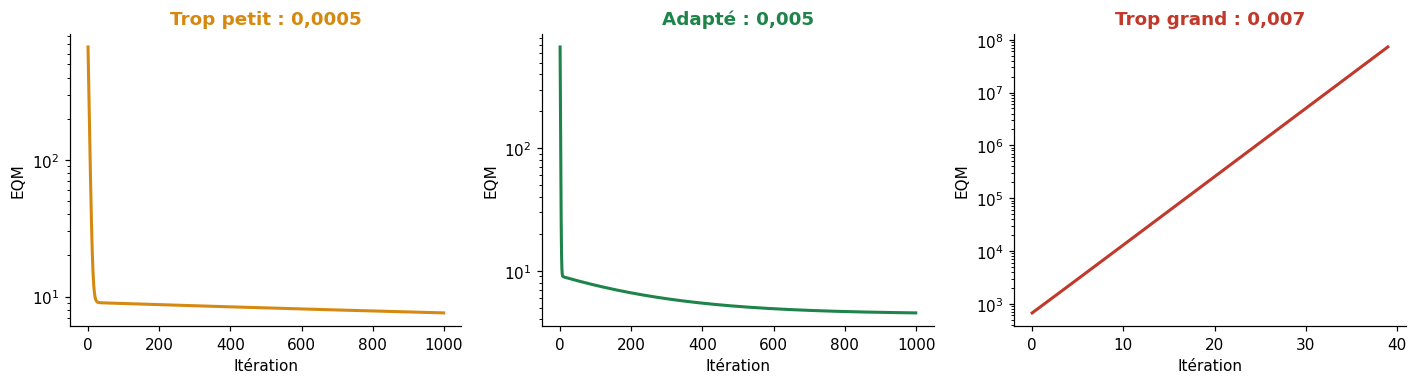

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (taux, titre, coul) in zip(axes, [(0.0005, "Trop petit : 0,0005", "#d68910"),
                                           (0.005,  "Adapté : 0,005", "#1e8449"),
                                           (0.007,  "Trop grand : 0,007", "#c0392b")]):
    _, _, h = descente_de_gradient(taux, n_iterations=1000 if taux < 0.006 else 40)
    ax.plot(h[:, 2], color=coul, lw=2); ax.set_yscale("log")
    ax.set_title(titre, color=coul, fontweight="bold"); ax.set_xlabel("Itération"); ax.set_ylabel("EQM")
plt.tight_layout(); plt.show()

- **Trop petit :** convergence très lente.
- **Adapté :** la perte diminue rapidement puis se stabilise au voisinage du minimum.
- **Trop grand :** chaque pas dépasse le minimum ; les paramètres oscillent avec une amplitude croissante et la perte **diverge**.

Dans la pratique, le choix du taux d'apprentissage est l'un des réglages les plus importants, en particulier pour les réseaux de neurones (atelier IA102).

## 6. Comparaison avec scikit-learn

Pour la régression linéaire avec l'EQM, le minimum peut être calculé directement par la méthode des **moindres carrés** (équations normales), sans itérations. C'est ce que fait `LinearRegression`.

In [ ]:
from sklearn.linear_model import LinearRegression

modele = LinearRegression().fit(distance.reshape(-1, 1), delai)
print(f"Moindres carrés (scikit-learn) : a = {modele.coef_[0]:.3f}, b = {modele.intercept_:.3f}, "
      f"EQM = {eqm(modele.predict(distance.reshape(-1, 1)), delai):.3f}")
print(f"Descente de gradient (1000 it.) : a = {a_appris:.3f}, b = {b_appris:.3f}, EQM = {hist[-1, 2]:.3f}")

Moindres carrés (scikit-learn) : a = 1.707, b = 5.073, EQM = 4.418
Descente de gradient (1000 it.) : a = 1.760, b = 4.344, EQM = 4.520


La descente de gradient s'approche de la solution exacte. Pour la plupart des modèles (régression logistique, réseaux de neurones), il n'existe pas de formule fermée : on utilise alors des méthodes itératives de ce type.

## 7. La généralisation

L'objectif n'est pas de minimiser l'erreur sur les données d'entraînement, mais d'obtenir de bonnes prédictions sur des **données nouvelles**. C'est la **généralisation**.

Comparons un modèle affine et un polynôme de degré 12, entraînés sur seulement 12 observations, puis évalués sur 200 observations nouvelles.

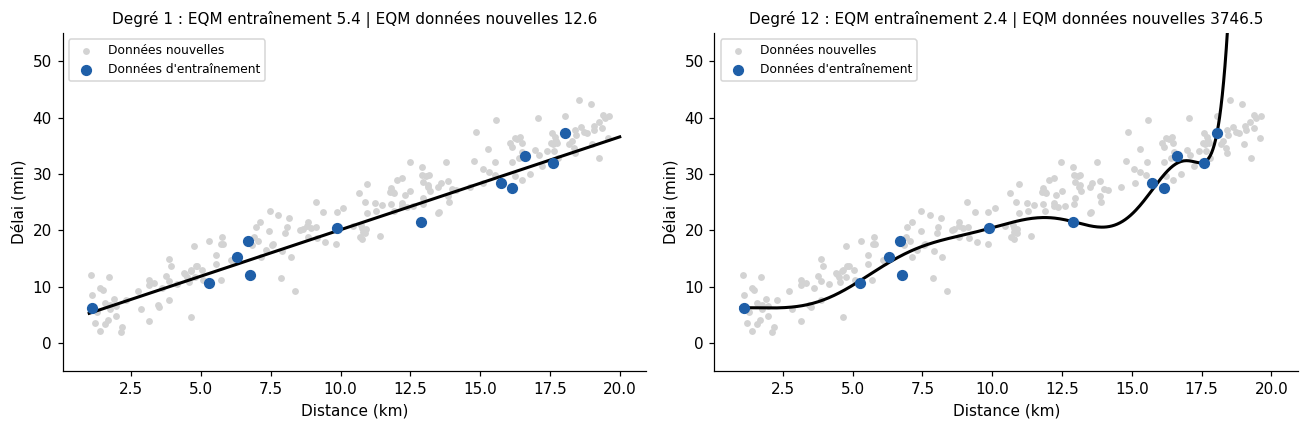

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(7)
x_ent = np.sort(rng.uniform(1, 20, 12)); y_ent = 1.8 * x_ent + 4 + rng.normal(0, 3, 12)
x_nouv = rng.uniform(1, 20, 200);       y_nouv = 1.8 * x_nouv + 4 + rng.normal(0, 3, 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, degre in zip(axes, [1, 12]):
    m = make_pipeline(PolynomialFeatures(degre), LinearRegression()).fit(x_ent.reshape(-1, 1), y_ent)
    xs = np.linspace(1, 20, 400).reshape(-1, 1)
    err_ent = eqm(m.predict(x_ent.reshape(-1, 1)), y_ent); err_nouv = eqm(m.predict(x_nouv.reshape(-1, 1)), y_nouv)
    ax.scatter(x_nouv, y_nouv, color="lightgray", s=12, label="Données nouvelles")
    ax.scatter(x_ent, y_ent, color="#1f5fa8", s=40, zorder=3, label="Données d'entraînement")
    ax.plot(xs, m.predict(xs), color="black", lw=2)
    ax.set_ylim(-5, 55); ax.set_xlabel("Distance (km)"); ax.set_ylabel("Délai (min)")
    ax.set_title(f"Degré {degre} : EQM entraînement {err_ent:.1f} | EQM données nouvelles {err_nouv:.1f}", fontsize=10)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

Le polynôme de degré 12 a une erreur d'entraînement plus faible, mais une erreur beaucoup plus élevée sur les données nouvelles : il a ajusté le **bruit** des 12 points plutôt que la tendance. C'est le **surapprentissage**.

Conséquence méthodologique, appliquée dans toute la suite de l'atelier : on réserve une partie des données, l'**ensemble de test**, que le modèle ne voit jamais pendant l'entraînement, afin d'estimer sa performance sur des données nouvelles.

### Synthèse : le cycle d'apprentissage

| Étape | Rôle | Dans cet exemple |
| --- | --- | --- |
| Modèle | Famille de fonctions paramétrées | $\hat{y} = a\,x + b$ |
| Perte | Mesure de l'erreur | EQM |
| Optimisation | Recherche des paramètres qui minimisent la perte | Descente de gradient ou moindres carrés |
| Évaluation | Mesure de la généralisation | Erreur sur un ensemble de test |

In [ ]:
quiz("Pendant la descente de gradient, la perte augmente à chaque itération. Quelle est la cause la plus probable ?",
     ["Le taux d'apprentissage est trop petit", "Le taux d'apprentissage est trop grand", "Le nombre d'itérations est insuffisant"],
     1, "Des pas trop grands dépassent le minimum : les paramètres oscillent et la perte diverge.")

In [ ]:
quiz("Que représente le gradient de la fonction de perte par rapport aux paramètres ?",
     ["La valeur minimale de la perte", "La direction de plus forte augmentation de la perte", "Le nombre d'itérations nécessaires"],
     1, "On se déplace donc dans la direction opposée au gradient pour réduire la perte.")

In [ ]:
quiz("Un modèle a une erreur presque nulle sur l'entraînement mais élevée sur des données nouvelles. Il s'agit de :",
     ["Sous-apprentissage", "Surapprentissage", "Un modèle bien ajusté"],
     1, "Le modèle a ajusté le bruit des données d'entraînement : il ne généralise pas.")

## À retenir

- Un **modèle** est une fonction paramétrée ; **apprendre** consiste à estimer ses paramètres.
- La **fonction de perte** (ici l'EQM) mesure l'erreur ; c'est une fonction des paramètres.
- Le **gradient** se calcule par dérivation (règle des fonctions composées) ; il indique la direction de plus forte augmentation de la perte.
- La **descente de gradient** met à jour les paramètres dans la direction opposée au gradient ; le **taux d'apprentissage** contrôle la taille des pas.
- L'objectif est la **généralisation** : on évalue toujours un modèle sur des données qu'il n'a pas vues.

**Notebook suivant :** 2 — Premier modèle de classification.